In [2]:
import numpy as np
import pandas as pd
from glob import glob
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from tqdm import tqdm
import yaml


In [4]:
from dataset import SmartPixelsDataset

# config = yaml.safe_load(open("config/v3.yml", "r"))
# config = yaml.safe_load(open("config/17180303/barrel-phys-pt/50x10.yml", "r"))
config = yaml.safe_load(open("config/10783560/v3.yml", "r"))

image_paths = [config['root'] + item[0] for item in config['train']]
label_paths = [config['root'] + item[1] for item in config['train']]

ds = SmartPixelsDataset(
    image_paths=image_paths,
    label_paths=label_paths,
    transform=lambda x, y: x.reshape((20, 13, 21)),
)


In [5]:
n_max = 10_000
all_x, all_y = [], []
for i, (x, y) in enumerate(tqdm(ds)):
    if i >= n_max:
        break
    all_x.append(x)
    all_y.append(y)

all_x = np.stack(all_x)
all_y = np.stack(all_y)

print(f"all_x shape: {all_x.shape}")
print(f"all_y shape: {all_y.shape}")


  0%|          | 0/5349672 [00:00<?, ?it/s]

  0%|          | 10000/5349672 [00:01<15:01, 5922.44it/s]


all_x shape: (10000, 20, 13, 21)
all_y shape: (10000, 13)


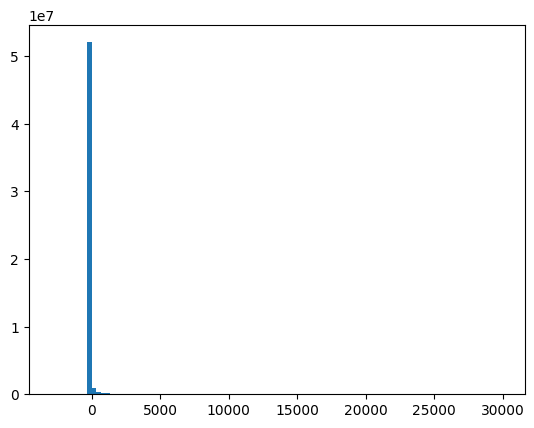

In [6]:
x_flat = all_x.flatten()

plt.hist(x_flat, bins=100)
plt.show()


['x-entry', 'y-entry', 'z-entry', 'n_x', 'n_y', 'n_z', 'number_eh_pairs', 'y-local', 'pt', 'cotAlpha', 'cotBeta', 'y-midplane', 'x-midplane']


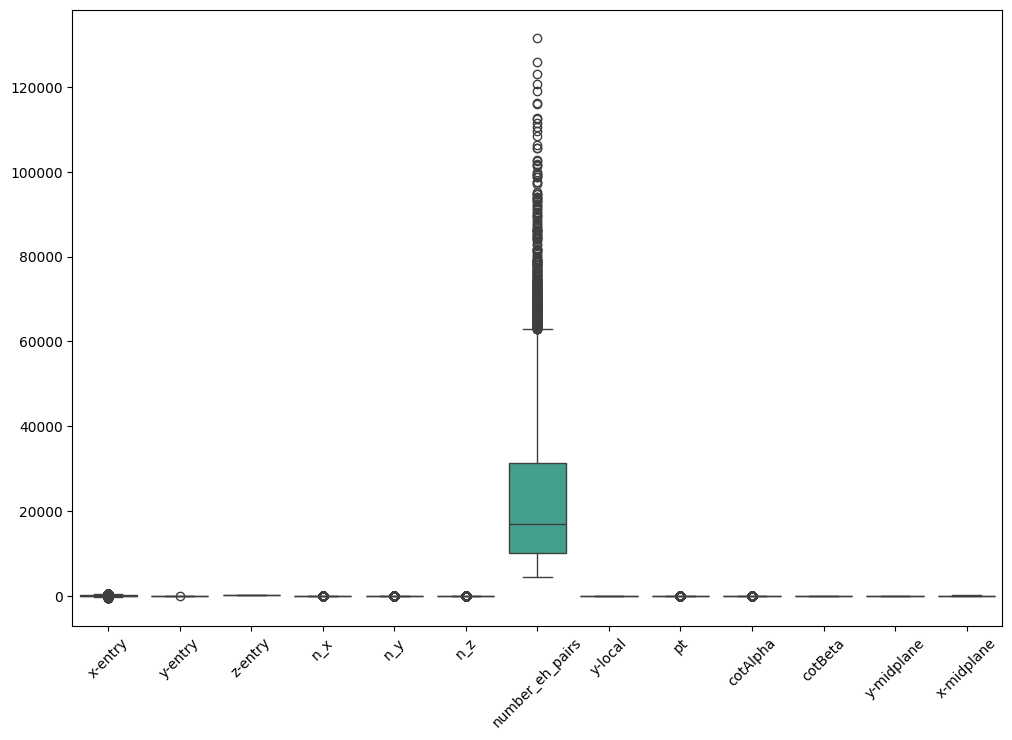

In [7]:
label_names = ds.label_names
print(label_names)

# make box plot
df = pd.DataFrame(all_y, columns=label_names)
plt.figure(figsize=(12, 8))
sns.boxplot(data=df)
plt.xticks(rotation=45)
plt.show()


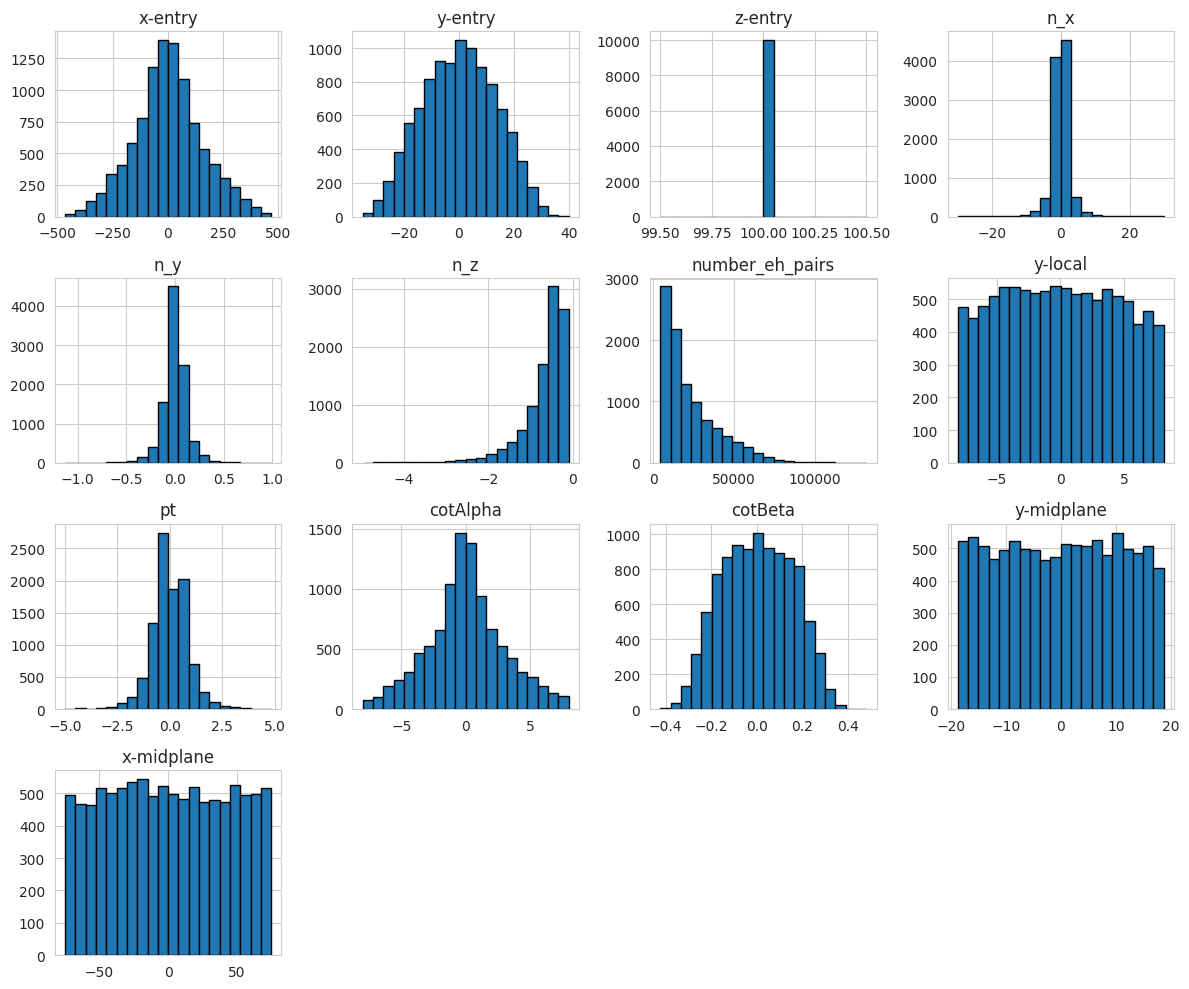

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

# Use seaborn's default style
sns.set_style("whitegrid")

# Create the histograms
df.hist(figsize=(12, 10), bins=20, edgecolor='black')
plt.tight_layout()
plt.show()

In [9]:
import importlib
import transform
importlib.reload(transform)
from transform import load_scaler
from transform import ReshapeTransform, SymLogTransform, NormalizeGlobal, NormalizeVector
from torchvision import transforms

(x_mean, x_std), (y_mean, y_std) = load_scaler(prefix="scaler")

print(f"{x_mean=}, {x_std=}")
print(f"{y_mean=}, {y_std=}")

my_trafo = transforms.Compose([
    SymLogTransform(),
    NormalizeGlobal(x_mean, x_std),
    ReshapeTransform((20, 13, 21)),
])

my_target_trafo = NormalizeVector(y_mean, y_std)


ds_scaled = SmartPixelsDataset(
    image_paths=image_paths,
    label_paths=label_paths,
    transform=my_trafo,
    target_transform=my_target_trafo,
)


ModuleNotFoundError: No module named 'transform'

In [49]:
n_max = 10_000
all_x_scaled, all_y_scaled = [], []
for i, (x, y) in enumerate(tqdm(ds_scaled)):
    if i >= n_max:
        break
    all_x_scaled.append(x)
    all_y_scaled.append(y)

all_x_scaled = np.stack(all_x_scaled)
all_y_scaled = np.stack(all_y_scaled)

print(f"all_x_scaled shape: {all_x_scaled.shape}")
print(f"all_y_scaled shape: {all_y_scaled.shape}")

  0%|          | 0/99991 [00:00<?, ?it/s]/Users/linogerlach/Projects/SmartPixels/SmartPixels/transform.py:142: RuntimeWarning: invalid value encountered in divide
  return (y - self.mean) / self.std
 10%|█         | 10000/99991 [00:01<00:09, 9418.16it/s]


all_x_scaled shape: (10000, 20, 13, 21)
all_y_scaled shape: (10000, 13)


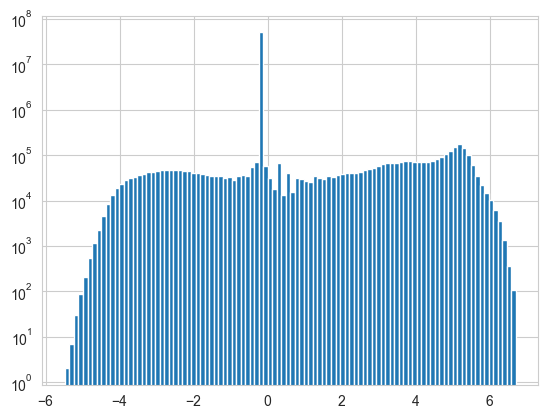

In [52]:
x_flat_scaled = all_x_scaled.flatten()

plt.hist(x_flat_scaled, bins=100)

plt.yscale('log')
# plt.hist(x_flat_scaled, bins=np.linspace(-3, 3, 100))
plt.show()


In [ ]:

label_names = ds_scaled.label_names
print(label_names)

# make box plot
df = pd.DataFrame(all_y_scaled, columns=label_names)
plt.figure(figsize=(12, 8))
sns.boxplot(data=df)
plt.xticks(rotation=45)
plt.show()

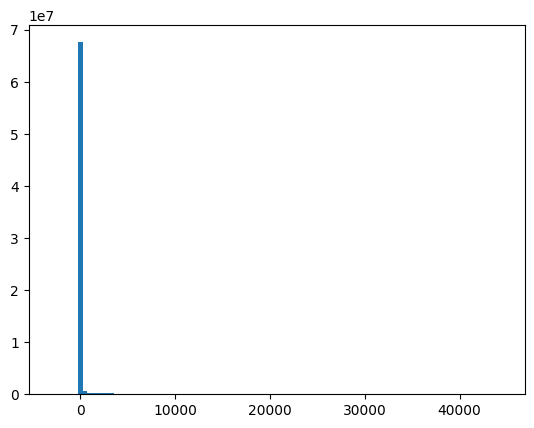

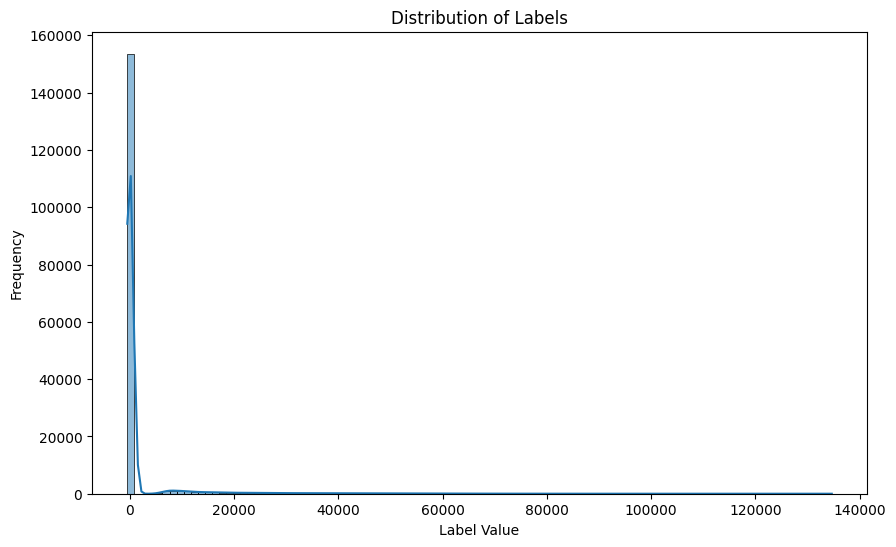

In [8]:
# make sns plot of all labels
y_flat = all_y.flatten()
plt.figure(figsize=(10, 6))
sns.histplot(y_flat, bins=100, kde=True)
plt.title("Distribution of Labels")
plt.xlabel("Label Value")
plt.ylabel("Frequency")
plt.show()